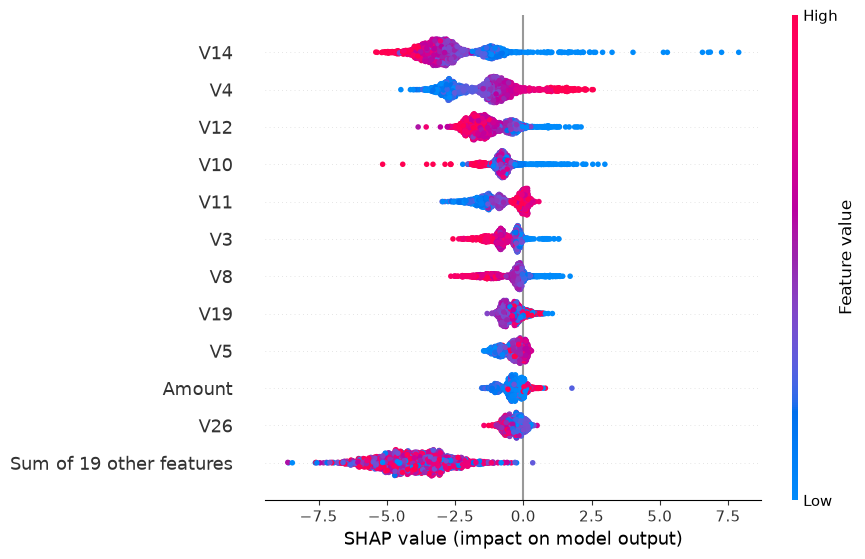

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

model = joblib.load("../models/best_model.pkl")
X_test = pd.read_csv("../data/X_test.csv")
y_test = pd.read_csv("../data/y_test.csv")["Class"]

explainer = shap.TreeExplainer(model)
sample = X_test.sample(2000, random_state=42)
shap_values = explainer(sample)

shap.plots.beeswarm(shap_values, max_display=12)

Fraud probability: 0.9999


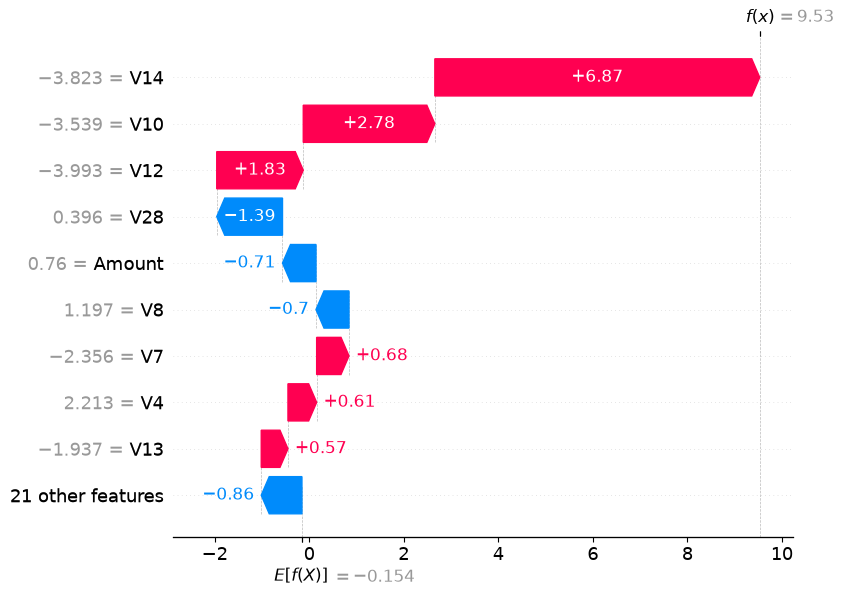

In [2]:
prob = model.predict_proba(X_test)[:, 1]
fraud_idx = X_test.index[(y_test == 1) & (prob >= 0.5)][0]
print("Fraud probability:", round(prob[fraud_idx], 4))

one = explainer(X_test.loc[[fraud_idx]])
shap.plots.waterfall(one[0], max_display=10)

In [3]:
sys.path.insert(0, "../src")
from safespend import build_features, score_statement, explain_statement

raw = pd.read_csv("../data/sample_statement.csv")
st = build_features(raw)
st, iso = score_statement(st)
st = explain_statement(st, iso)

for _, r in st.sort_values("risk_score", ascending=False).head(10).iterrows():
    print(f"{r['level']}  {r['risk_score']:.0f}/100  {r['datetime']:%d %b %Y %I:%M %p}  "
          f"{r['merchant']}  ₹{r['amount']:,.0f}  ({r['city']})")
    for reason in r["reasons"]:
        print("     •", reason)
    print()

🔴 High risk  100/100  03 Jul 2026 03:15 AM  Intl Electronics Ltd  ₹68,999  (Singapore)
     • ₹68,999 is 83× your usual spend of ₹832
     • Made at 03:15 AM; you usually pay between 10:00 and 19:00
     • Only 3 min after your previous payment
     • Made in Singapore; you usually transact in Chennai
     • You have rarely or never paid 'Intl Electronics Ltd' before

🔴 High risk  97/100  03 Jul 2026 03:12 AM  Intl Electronics Ltd  ₹72,999  (Singapore)
     • ₹72,999 is 88× your usual spend of ₹832
     • Made at 03:12 AM; you usually pay between 10:00 and 19:00
     • Made in Singapore; you usually transact in Chennai
     • You have rarely or never paid 'Intl Electronics Ltd' before

🔴 High risk  95/100  02 Sep 2026 04:06 AM  Gift Card Store  ₹25,000  (Kolkata)
     • ₹25,000 is 30× your usual spend of ₹832
     • Only 1 min after your previous payment
     • Made at 04:06 AM; you usually pay between 10:00 and 19:00
     • Made in Kolkata; you usually transact in Chennai
     • You h

## Findings
- SHAP (global): V14, V4, V12, V10, V11 drive the XGBoost model — the same features EDA correlation found.
- SHAP (local): for a caught fraud (p = 0.9999), low V14 contributed +6.87 log-odds, followed by V10 and V12.
- Statement alerts: each risky transaction gets plain-language reasons built from the user's own numbers, ordered by SHAP importance.